# Learning-Based Nonlinear System Identification
This notebook uses simulated input–state data to identify a discrete-time model of a nonlinear cart–pole system. It covers three common approaches: a multilayer perceptron (MLP), Gaussian Processes (GPs), and a physics-informed model with a learned residual.


## 0. Mathematical setup and notation

The state of the cart–pole system is

$$
 x_k = \begin{bmatrix} p_k & \theta_k & v_k & \omega_k \end{bmatrix}^{\mathsf T},
$$

where $p$ is cart position $[m]$, $\theta$ is the pole angle $[rad]$, $v=\dot p$ is cart velocity $[m/s]$, and $\omega=\dot\theta$ is angular velocity $[rad/s]$. The angle is measured from the upright vertical position. The input $u_k$ is the horizontal force applied to the cart $[N]$.

The continuous-time dynamics are written as

$$
\dot{x}(t)=f(x(t),u(t)).
$$

After numerical integration over one sampling interval $T_s$, the discrete-time system is

$$
x_{k+1}=F_{T_s}(x_k,u_k).
$$

The models in this notebook receive the current state and input as one feature vector:

$$
z_k=\begin{bmatrix}x_k^{\mathsf T}&u_k\end{bmatrix}^{\mathsf T}\in\mathbb R^5.
$$

They learn the state increment

$$
\Delta x_k=x_{k+1}-x_k,
$$

and reconstruct the next state using

$$
\widehat{x}_{k+1}=x_k+\widehat{\Delta x}_k.
$$

Learning the increment keeps the prediction target focused on the change over one sample. It can make the target easier to scale, although it does not guarantee a lower prediction error.

## 1. Environment and dependencies



In [2]:
# Install required packages
%pip -q install gpytorch scikit-learn matplotlib

## 2. Imports and reproducibility


In [3]:
import copy
import random
import math
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import gpytorch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic CuDNN behavior improves reproducibility when available.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"GPyTorch: {gpytorch.__version__}")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cpu
PyTorch: 2.14.1+cpu
GPyTorch: 1.15.2


## 3. Continuous-time cart–pole equations

The pole is modelled as a uniform rod with its centre of mass at a distance $l$ from the pivot. Its moment of inertia about the centre of mass is

$$
I_c=\frac{1}{3}m_p l^2,
$$

which corresponds to a rod of total length $2l$. Let $m_c$ be the cart mass, $m_p$ the pole mass, and $M=m_c+m_p$ the total mass.

With the angle measured from the upright position, the equations used in the simulator can be written as

$$
q=\frac{u+m_p l\omega^2\sin\theta}{M},
$$

$$
\dot\omega=\ddot\theta=
\frac{g\sin\theta-q\cos\theta}
{l\left(\frac{4}{3}-\frac{m_p\cos^2\theta}{M}\right)},
$$

$$
\dot v=\ddot p=q-\frac{m_p l\dot\omega\cos\theta}{M}.
$$

For the state ordering used here,

$$
f(x,u)=\begin{bmatrix}v&\omega&\dot v&\dot\omega\end{bmatrix}^{\mathsf T}.
$$

At $\theta=0\$, the pole is upright. This equilibrium is unstable without feedback control. The simulator uses the same equations and parameters for all data sets. The learning models receive only the resulting state and input transitions.

The default parameters are $m_c=1.0\,\mathrm{kg}$, $m_p=0.1$,$\mathrm{kg}$, $l=0.5$,$\mathrm{m}$, and $g=9.81$,$\mathrm{m/s^2}$.

In [4]:
class CartPole:
    """Frictionless cart-pole model with state [p, theta, v, omega]."""

    def __init__(self, m_c=1.0, m_p=0.1, l=0.5, g=9.81):
        self.m_c = float(m_c)
        self.m_p = float(m_p)
        self.l = float(l)  # distance from pivot to pole center of mass
        self.g = float(g)
        self.state_dim = 4
        self.action_dim = 1

    def dynamics(self, state, u):
        """Evaluate the continuous-time state derivative."""
        p, theta, v, omega = state
        total_mass = self.m_c + self.m_p

        sin_theta = np.sin(theta)
        cos_theta = np.cos(theta)

        q = (u + self.m_p * self.l * omega**2 * sin_theta) / total_mass

        omega_dot = (self.g * sin_theta - cos_theta * q) / (
            self.l * (4.0 / 3.0 - self.m_p * cos_theta**2 / total_mass))

        v_dot = q - (self.m_p * self.l * omega_dot * cos_theta / total_mass)

        return np.array([v, omega, v_dot, omega_dot], dtype=float)

    def rk4_step(self, state, u, dt):
        """Advance the state by one RK4 step with fixed input."""
        k1 = self.dynamics(state, u)
        k2 = self.dynamics(state + 0.5 * dt * k1, u)
        k3 = self.dynamics(state + 0.5 * dt * k2, u)
        k4 = self.dynamics(state + dt * k3, u)
        return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

    def simulate(self, x0, controller, t_end, dt=0.05):
        """Simulate one trajectory; controller(state, time) returns force [N]."""
        n_steps = int(round(t_end / dt))
        time = np.arange(n_steps + 1) * dt
        states = np.zeros((n_steps + 1, self.state_dim), dtype=float)
        inputs = np.zeros(n_steps, dtype=float)
        states[0] = np.asarray(x0, dtype=float)

        for k in range(n_steps):
            inputs[k] = float(controller(states[k], time[k]))
            states[k + 1] = self.rk4_step(states[k], inputs[k], dt)

        return time, states, inputs

# Instantiate the plant and verify the state derivative at the upright equilibrium.
plant = CartPole()
x_equilibrium = np.zeros(4)
print("f(0, 0) =", plant.dynamics(x_equilibrium, 0.0))
assert np.allclose(plant.dynamics(x_equilibrium, 0.0), np.zeros(4))

f(0, 0) = [0. 0. 0. 0.]


## 4. Numerical integration with RK4

The continuous-time equations are integrated with a fixed sampling period $T_s$. During one interval, the force is held constant. For $\dot x=f(x,u)$, the fourth-order Runge–Kutta method computes

$$
\begin{aligned}
k_1&=f(x_k,u_k),\\
k_2&=f\left(x_k+\frac{T_s}{2}k_1,u_k\right),\\
k_3&=f\left(x_k+\frac{T_s}{2}k_2,u_k\right),\\
k_4&=f(x_k+T_s k_3,u_k),\\
x_{k+1}&=x_k+\frac{T_s}{6}(k_1+2k_2+2k_3+k_4).
\end{aligned}
$$

For smooth dynamics, RK4 has local truncation error of order $O(T_s^5)$ and global error of order $O(T_s^4)$. It is an approximation to the continuous-time solution, not an exact discretisation.

The default sampling period is $T_s=0.05$,$\mathrm{s}$. Data generation and the known-physics reference use the same integration step.

In [5]:
DT = 0.05
T_END = 3.0

## 3. Data Generation
The first experiment focuses on a limited operating region around the upright position. This makes it easier to inspect the learned models before testing more demanding conditions.

Each trajectory starts from a different initial state. A state-feedback term keeps the pole near the upright position, and a bounded disturbance is added to produce a range of input–state transitions:

$$
u_k=\operatorname{sat}_{[-u_{\max},u_{\max}]}
\left(K_p p_k+K_\theta\theta_k+K_v v_k+K_\omega\omega_k+d_k\right).
$$

Here, $d_k$ is a random value that is held for several samples before being changed. The feedback gains and force limit are set in the code cell below. This is a simple data-collection policy, not an optimal excitation design.

Training, validation, and test data are generated from separate groups of trajectories with different random seeds. The same collection policy is used for all three groups.

In [6]:
# Feedback keeps the trajectories near the upright position.
# A bounded disturbance is added so the data contain different inputs.
K_P = 1.0
K_THETA = 50.0
K_V = 2.0
K_OMEGA = 10.0
FORCE_LIMIT = 10.0
DISTURBANCE_AMPLITUDE = 2.0
DISTURBANCE_HOLD_STEPS = 4  # 0.20 s at DT = 0.05 s


def generate_trajectory(plant, rng, t_end=T_END, dt=DT):
    """Simulate one trajectory near the upright position."""
    x0 = np.array([
        rng.uniform(-0.5, 0.5),   # cart position [m]
        rng.uniform(-0.3, 0.3),   # pole angle [rad]
        rng.uniform(-0.3, 0.3),   # cart velocity [m/s]
        rng.uniform(-0.5, 0.5),   # angular velocity [rad/s]
    ])

    disturbance = {"value": 0.0}

    def excited_feedback_controller(state, time):
        step = int(round(time / dt))
        if step % DISTURBANCE_HOLD_STEPS == 0:
            disturbance["value"] = rng.uniform(
                -DISTURBANCE_AMPLITUDE,
                DISTURBANCE_AMPLITUDE
            )

        p, theta, v, omega = state
        feedback_force = (
            K_P * p + K_THETA * theta + K_V * v + K_OMEGA * omega
        )
        force = feedback_force + disturbance["value"]
        return np.clip(force, -FORCE_LIMIT, FORCE_LIMIT)

    time, states, inputs = plant.simulate(
        x0=x0,
        controller=excited_feedback_controller,
        t_end=t_end,
        dt=dt
    )

    return {"time": time, "states": states, "inputs": inputs}


def generate_trajectories(plant, n_trajectories, seed):
    """Generate independent trajectories from a dedicated random generator."""
    rng = np.random.default_rng(seed)
    return [generate_trajectory(plant, rng) for _ in range(n_trajectories)]


train_trajectories = generate_trajectories(plant, n_trajectories=20, seed=SEED + 1)
val_trajectories = generate_trajectories(plant, n_trajectories=5, seed=SEED + 2)
test_trajectories = generate_trajectories(plant, n_trajectories=8, seed=SEED + 3)

print(
    f"Trajectories: train={len(train_trajectories)}, "
    f"validation={len(val_trajectories)}, test={len(test_trajectories)}"
)

Trajectories: train=20, validation=5, test=8


## 6. Build the transition data set

For each simulated trajectory, the state sequence is $x_0,\ldots,x_N$, and the input sequence is $u_0,\ldots,u_{N-1}$. Each sample represents one transition:

$$
z_k=\begin{bmatrix}x_k^{\mathsf T}&u_k\end{bmatrix}^{\mathsf T},
\qquad
\Delta x_k=x_{k+1}-x_k.
$$

The code stores the original trajectories and also stacks their transitions into arrays. The arrays are used for one-step model training. The trajectory structure is kept for rollout evaluation, where the order of the samples matters.

In [7]:
STATE_NAMES = ["Cart position", "Pole angle", "Cart velocity", "Angular velocity"]
STATE_UNITS = ["m", "rad", "m/s", "rad/s"]


def pack_transitions(trajectories):
    """Stack trajectory transitions into arrays for model fitting."""
    X_parts, U_parts, X_next_parts = [], [], []

    for trajectory in trajectories:
        states = trajectory["states"]
        inputs = trajectory["inputs"]

        X_parts.append(states[:-1])
        U_parts.append(inputs.reshape(-1, 1))
        X_next_parts.append(states[1:])

    X = np.vstack(X_parts)
    U = np.vstack(U_parts)
    X_next = np.vstack(X_next_parts)
    Z = np.hstack([X, U])
    Delta = X_next - X

    return Z, Delta, X, U, X_next


Z_train, D_train, X_train, U_train, X_next_train = pack_transitions(train_trajectories)
Z_val, D_val, X_val, U_val, X_next_val = pack_transitions(val_trajectories)
Z_test, D_test, X_test, U_test, X_next_test = pack_transitions(test_trajectories)

print("Training transitions:", Z_train.shape, D_train.shape)
print("Validation transitions:", Z_val.shape, D_val.shape)
print("Test transitions:", Z_test.shape, D_test.shape)

Training transitions: (4000, 5) (4000, 4)
Validation transitions: (1000, 5) (1000, 4)
Test transitions: (1600, 5) (1600, 4)


## 7. Check the data before model fitting

Before training, inspect a few trajectories and the range of each state and input. A model can interpolate well only in regions that are represented by the training data. Large errors outside that region may be caused by extrapolation rather than by the network architecture.

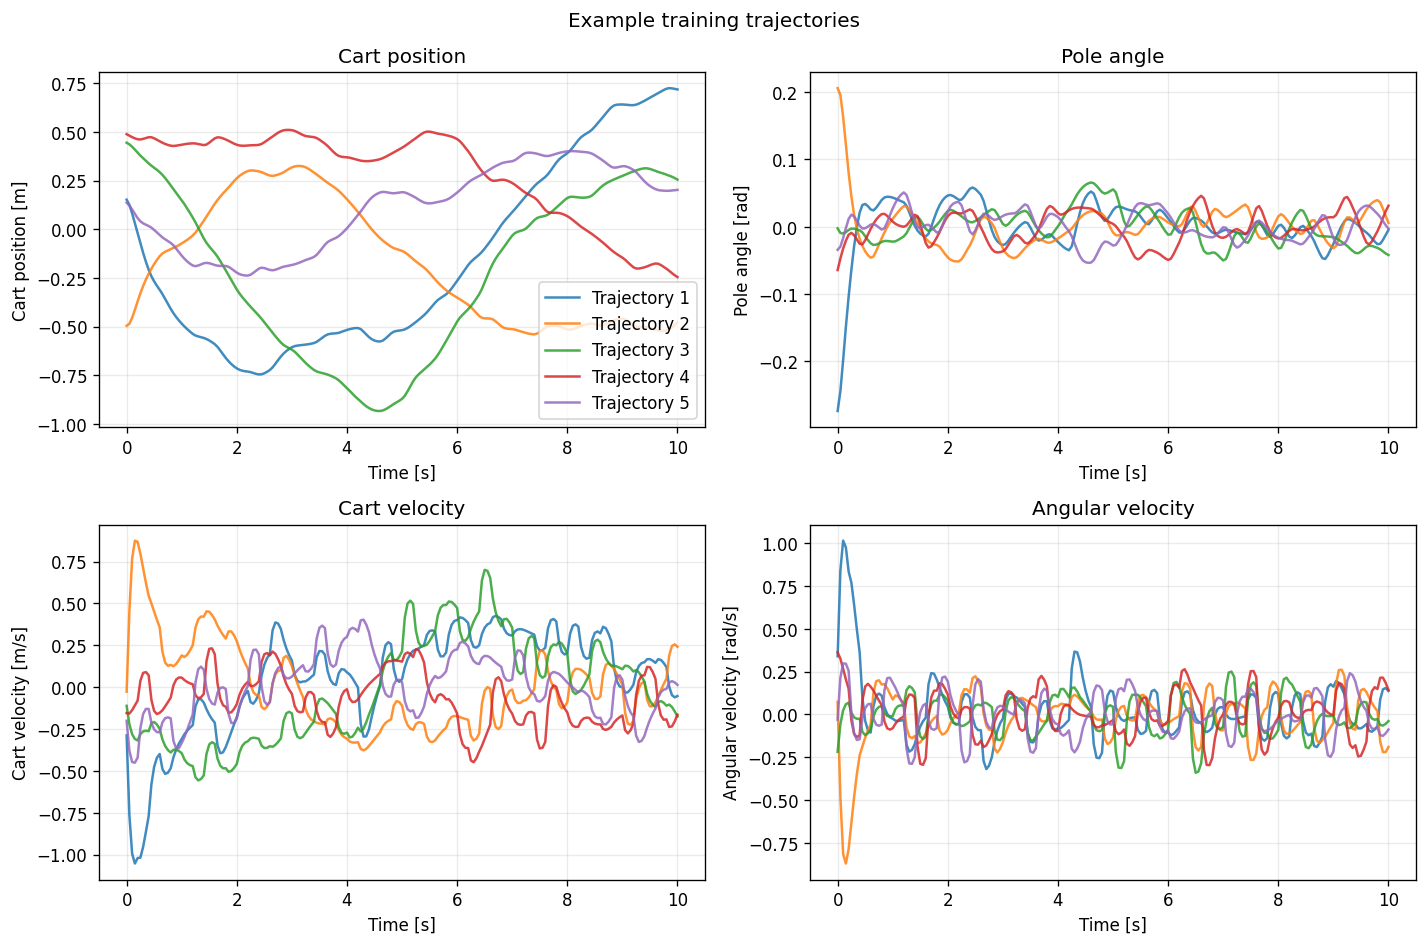

Training state minima: [-1.248 -0.286 -1.141 -1.118]
Training state maxima: [1.271 0.268 1.193 1.014]
Training input range [N]: (np.float64(-10.0), np.float64(10.0))


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for d, ax in enumerate(axes.flat):
    for i, trajectory in enumerate(train_trajectories[:5]):
        ax.plot(
            trajectory["time"],
            trajectory["states"][:, d],
            alpha=0.85,
            label=f"Trajectory {i+1}" if d == 0 else None
        )
    ax.set_title(STATE_NAMES[d])
    ax.set_xlabel("Time [s]")
    ax.set_ylabel(f"{STATE_NAMES[d]} [{STATE_UNITS[d]}]")

axes[0, 0].legend()
plt.suptitle("Example training trajectories")
plt.tight_layout()
plt.show()

print("Training state minima:", np.round(X_train.min(axis=0), 3))
print("Training state maxima:", np.round(X_train.max(axis=0), 3))
print("Training input range [N]:", (round(U_train.min(), 3), round(U_train.max(), 3)))

## 8. Standardise the data using the training set

The five input features and four state increments have different units and ranges. We standardise them using the training data:

$$
z_k^{(n)}=\frac{z_k-\mu_z}{s_z},
\qquad
\Delta x_k^{(n)}=\frac{\Delta x_k-\mu_\Delta}{s_\Delta},
$$

where the division is element-wise. The means and standard deviations are calculated from the training set only. The same values are then used for validation and test data. This avoids using information from the test set during model development.

After prediction, the increment is converted back to physical units:

$$
\widehat{\Delta x}_k=s_\Delta\odot\widehat{\Delta x}_k^{(n)}+\mu_\Delta.
$$

In [9]:
scaler_Z = StandardScaler()
scaler_D = StandardScaler()

Z_train_n = scaler_Z.fit_transform(Z_train)
D_train_n = scaler_D.fit_transform(D_train)

Z_val_n = scaler_Z.transform(Z_val)
D_val_n = scaler_D.transform(D_val)

Z_test_n = scaler_Z.transform(Z_test)
D_test_n = scaler_D.transform(D_test)

# Standard deviations are also used to report dimensionless NRMSE.
state_scale = np.std(X_train, axis=0)
state_scale = np.maximum(state_scale, 1e-8)

print("Feature scaler means:", np.round(scaler_Z.mean_, 4))
print("Increment scaler means:", np.round(scaler_D.mean_, 6))
print("Increment scaler scales:", np.round(scaler_D.scale_, 6))

Feature scaler means: [ 0.0122  0.0006 -0.0066 -0.0013  0.0064]
Increment scaler means: [-3.21e-04 -6.40e-05  2.94e-04 -2.50e-05]
Increment scaler scales: [0.012081 0.007647 0.062875 0.081985]


## 9. Model 1 — Multilayer perceptron

The MLP approximates the state-increment map:

$$
\widehat{\Delta x}^{(n)}_k=\phi_\vartheta(z_k^{(n)}),
$$

where $\phi_\vartheta$ is a feed-forward neural network with trainable parameters $\vartheta$. The implementation uses three hidden layers with the $\tanh$ activation function.

The network is trained by minimising the mean squared error

$$
J(\vartheta)=\frac{1}{N_{\mathrm{tr}}}
\sum_{k=1}^{N_{\mathrm{tr}}}
\left\|\phi_\vartheta(z_k^{(n)})-\Delta x_k^{(n)}\right\|_2^2.
$$

Validation loss is used for learning-rate reduction and early stopping. The test set is not used to choose the model or its training duration.

In [10]:
class DynamicsMLP(nn.Module):
    def __init__(self, input_dim=5, hidden_dim=128, output_dim=4):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, z_normalized):
        return self.network(z_normalized)


def train_supervised_model(
    model,
    Z_train_array,
    Y_train_array,
    Z_val_array,
    Y_val_array,
    epochs=300,
    batch_size=128,
    learning_rate=1e-3,
    patience=30,
    trainable_parameters=None,
    description="Training model"
):
    """Train a model and keep the weights with the lowest validation loss."""
    model = model.to(device)
    parameters = (
        trainable_parameters
        if trainable_parameters is not None
        else model.parameters()
    )

    optimizer = optim.AdamW(parameters, lr=learning_rate, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=8
    )
    criterion = nn.MSELoss()

    train_dataset = TensorDataset(
        torch.tensor(Z_train_array, dtype=torch.float32),
        torch.tensor(Y_train_array, dtype=torch.float32)
    )
    loader_generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=loader_generator
    )

    Z_val_tensor = torch.tensor(Z_val_array, dtype=torch.float32, device=device)
    Y_val_tensor = torch.tensor(Y_val_array, dtype=torch.float32, device=device)

    history = {"train_loss": [], "validation_loss": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        n_seen = 0

        for z_batch, y_batch in train_loader:
            z_batch = z_batch.to(device)
            y_batch = y_batch.to(device)

            prediction = model(z_batch)
            loss = criterion(prediction, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(z_batch)
            n_seen += len(z_batch)

        train_loss = running_loss / max(n_seen, 1)

        model.eval()
        with torch.no_grad():
            validation_prediction = model(Z_val_tensor)
            validation_loss = criterion(validation_prediction, Y_val_tensor).item()

        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        scheduler.step(validation_loss)

        if validation_loss < best_val_loss - 1e-6:
            best_val_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"{description}: early stopping at epoch {epoch + 1}")
            break

    model.load_state_dict(best_state)
    print(f"{description}: best validation MSE = {best_val_loss:.6f}")
    return model, history


nn_model = DynamicsMLP()
nn_model, nn_history = train_supervised_model(
    nn_model,
    Z_train_n, D_train_n,
    Z_val_n, D_val_n,
    epochs=300,
    learning_rate=1e-3,
    description="MLP"
)

MLP: early stopping at epoch 132
MLP: best validation MSE = 0.000737


### Check the MLP learning curves

The training and validation curves help show whether the network is fitting the data consistently. A much lower training loss than validation loss can indicate overfitting. If both losses remain high, the model may be too simple, the data may not cover the operating region, or the optimiser may need adjustment.

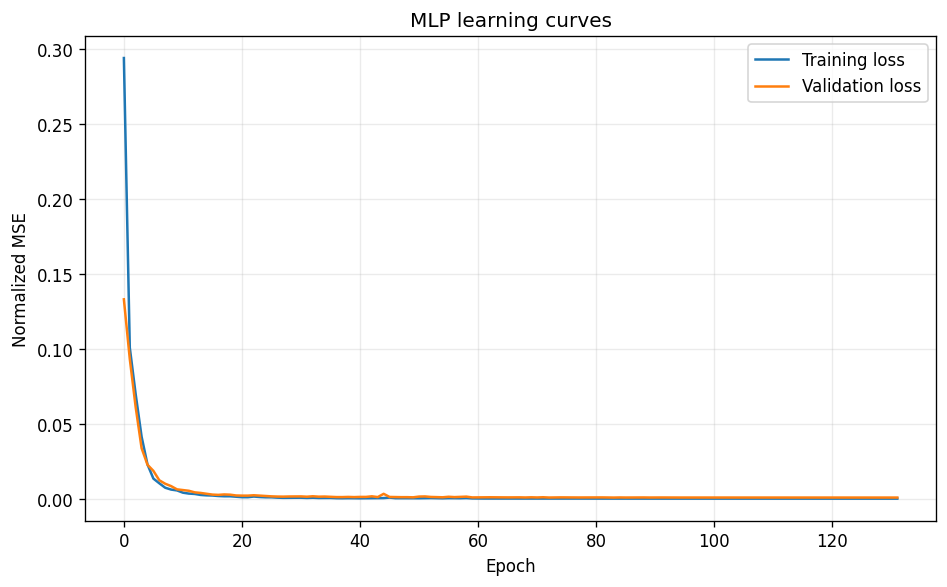

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(nn_history["train_loss"], label="Training loss")
plt.plot(nn_history["validation_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("MLP learning curves")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Model 2 — Gaussian Processes

Four independent Gaussian Processes are fitted, one for each component of the state increment. For output component $j$, the regression model is

$$
\Delta x_{k,j}^{(n)}=g_j(z_k^{(n)})+\epsilon_{k,j},
\qquad
\epsilon_{k,j}\sim\mathcal N(0,\sigma_{n,j}^2).
$$

The implementation uses a constant mean function and a Matérn kernel with $\nu=2.5$. Automatic relevance determination (ARD) gives the kernel a separate length scale for each input feature.

The GP returns a predictive mean and variance. The variance is useful because it gives an indication of where the model has less information. Exact GP training becomes expensive as the number of training samples grows, so the optional data-efficiency experiment may take longer than the MLP experiment.

In [12]:
class ExactGPScalar(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood):
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=2.5,
                ard_num_dims=train_x.shape[-1]
            )
        )

    def forward(self, x):
        mean = self.mean_module(x)
        covariance = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean, covariance)


def gaussian_nll_pointwise(mean, variance, target):
    variance = variance.clamp_min(1e-8)
    return 0.5 * (torch.log(2.0 * math.pi * variance) + (target - mean)**2 / variance).mean()


def train_gp_multioutput(
    Z_train_array,
    D_train_array,
    Z_val_array,
    D_val_array,
    training_iterations=70,
    learning_rate=0.06,
    patience=12
):
    """Fit one exact GP for each state-increment component."""
    train_x = torch.tensor(Z_train_array, dtype=torch.float32, device=device)
    val_x = torch.tensor(Z_val_array, dtype=torch.float32, device=device)
    train_y_all = torch.tensor(D_train_array, dtype=torch.float32, device=device)
    val_y_all = torch.tensor(D_val_array, dtype=torch.float32, device=device)

    models, likelihoods, histories = [], [], []

    for output_index in range(train_y_all.shape[1]):
        print(f"Training GP output {output_index + 1}/{train_y_all.shape[1]}")
        train_y = train_y_all[:, output_index]
        val_y = val_y_all[:, output_index]

        likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
        model = ExactGPScalar(train_x, train_y, likelihood).to(device)

        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
        marginal_log_likelihood = gpytorch.mlls.ExactMarginalLogLikelihood(
            likelihood, model
        )

        best_val = float("inf")
        best_model_state = copy.deepcopy(model.state_dict())
        best_likelihood_state = copy.deepcopy(likelihood.state_dict())
        no_improvement = 0
        train_losses, val_losses = [], []

        for iteration in range(training_iterations):
            model.train()
            likelihood.train()
            optimizer.zero_grad()

            output = model(train_x)
            loss = -marginal_log_likelihood(output, train_y)
            loss.backward()
            optimizer.step()
            train_losses.append(float(loss.item()))

            model.eval()
            likelihood.eval()
            with torch.no_grad(), gpytorch.settings.fast_pred_var():
                validation_distribution = likelihood(model(val_x))
                val_loss = gaussian_nll_pointwise(
                    validation_distribution.mean,
                    validation_distribution.variance,
                    val_y
                ).item()

            val_losses.append(val_loss)

            if val_loss < best_val - 1e-5:
                best_val = val_loss
                best_model_state = copy.deepcopy(model.state_dict())
                best_likelihood_state = copy.deepcopy(likelihood.state_dict())
                no_improvement = 0
            else:
                no_improvement += 1

            if no_improvement >= patience:
                break

        model.load_state_dict(best_model_state)
        likelihood.load_state_dict(best_likelihood_state)
        model.eval()
        likelihood.eval()

        models.append(model)
        likelihoods.append(likelihood)
        histories.append({"train_nll": train_losses, "validation_nll": val_losses})
        print(f"  Best validation NLL: {best_val:.5f}")

    return models, likelihoods, histories


def predict_gp_multioutput(models, likelihoods, Z_array):
    """Return the standardised predictive mean and variance."""
    test_x = torch.tensor(Z_array, dtype=torch.float32, device=device)
    means, variances = [], []

    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        for model, likelihood in zip(models, likelihoods):
            model.eval()
            likelihood.eval()
            predictive_distribution = likelihood(model(test_x))
            means.append(predictive_distribution.mean.cpu().numpy())
            variances.append(predictive_distribution.variance.cpu().numpy())

    return np.stack(means, axis=1), np.stack(variances, axis=1)


gp_models, gp_likelihoods, gp_history = train_gp_multioutput(
    Z_train_n, D_train_n,
    Z_val_n, D_val_n,
    training_iterations=70,
    learning_rate=0.06
)

Training GP output 1/4
  Best validation NLL: -1.08820
Training GP output 2/4
  Best validation NLL: -1.13445
Training GP output 3/4
  Best validation NLL: -1.14824
Training GP output 4/4
  Best validation NLL: -1.13536


## 11. Model 3 — Physics-informed residual model

The hybrid model combines a physics-based prediction with a neural correction. Let $F_{\mathrm{prior}}$ be the discrete-time prediction obtained from the cart–pole equations using the parameters stored in the hybrid model. Its increment is

$$
\Delta x_{\mathrm{prior}}=F_{\mathrm{prior}}(x_k,u_k)-x_k.
$$

The network learns the remaining error:

$$
\widehat{\Delta x}_k
=\Delta x_{\mathrm{prior}}+r_\vartheta(x_k,u_k).
$$

In the implementation, the physical prediction is converted to the same standardised increment coordinates as the training target before the residual is added. The input is converted back to physical units before the equations are evaluated.


In [13]:
class HybridResidualModel(nn.Module):
    """Combine a physical RK4 prediction with a learned residual."""

    def __init__(self, plant, scaler_Z, scaler_D, dt=DT, hidden_dim=64,
                 mass_cart_factor=1.08, mass_pole_factor=0.92, length_factor=1.05):
        super().__init__()

        # The prior parameters differ slightly from the simulator parameters.
        self.m_c = plant.m_c * mass_cart_factor
        self.m_p = plant.m_p * mass_pole_factor
        self.l = plant.l * length_factor
        self.g = plant.g
        self.dt = float(dt)

        # Keep the training-set scaling values with the model.
        self.register_buffer("z_mean", torch.tensor(scaler_Z.mean_, dtype=torch.float32))
        self.register_buffer("z_scale", torch.tensor(scaler_Z.scale_, dtype=torch.float32))
        self.register_buffer("d_mean", torch.tensor(scaler_D.mean_, dtype=torch.float32))
        self.register_buffer("d_scale", torch.tensor(scaler_D.scale_, dtype=torch.float32))

        self.residual_network = nn.Sequential(
            nn.Linear(5, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 4)
        )

    def continuous_dynamics_torch(self, state, force):
        p, theta, v, omega = state.unbind(dim=1)
        total_mass = self.m_c + self.m_p

        sin_theta = torch.sin(theta)
        cos_theta = torch.cos(theta)
        q = (force + self.m_p * self.l * omega**2 * sin_theta) / total_mass

        omega_dot = (
            self.g * sin_theta - cos_theta * q
        ) / (
            self.l * (4.0 / 3.0 - self.m_p * cos_theta**2 / total_mass)
        )

        v_dot = q - self.m_p * self.l * omega_dot * cos_theta / total_mass
        return torch.stack([v, omega, v_dot, omega_dot], dim=1)

    def rk4_torch(self, state, force):
        dt = self.dt
        k1 = self.continuous_dynamics_torch(state, force)
        k2 = self.continuous_dynamics_torch(state + 0.5 * dt * k1, force)
        k3 = self.continuous_dynamics_torch(state + 0.5 * dt * k2, force)
        k4 = self.continuous_dynamics_torch(state + dt * k3, force)
        return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

    def forward(self, z_normalized):
        # Convert standardized features back to physical units.
        z_physical = z_normalized * self.z_scale + self.z_mean
        state = z_physical[:, :4]
        force = z_physical[:, 4]

        # Keep this calculation differentiable for sequence training.
        next_state_physics = self.rk4_torch(state, force)
        delta_physics = next_state_physics - state

        # Standardize the physics increment before adding the learned residual.
        delta_physics_normalized = (delta_physics - self.d_mean) / self.d_scale
        residual_normalized = self.residual_network(z_normalized)
        return delta_physics_normalized + residual_normalized


hybrid_model = HybridResidualModel(plant, scaler_Z, scaler_D).to(device)
hybrid_model, hybrid_history = train_supervised_model(
    hybrid_model,
    Z_train_n, D_train_n,
    Z_val_n, D_val_n,
    epochs=300,
    learning_rate=1e-3,
    trainable_parameters=hybrid_model.residual_network.parameters(),
    description="Hybrid residual model"
)

Hybrid residual model: early stopping at epoch 177
Hybrid residual model: best validation MSE = 0.000008


## 12. One-step prediction on the test trajectories

For each test transition, the model predicts an increment and the next state is reconstructed as

$$
\widehat x_{k+1}=x_k+\widehat{\Delta x}_k.
$$

We report the root mean squared error for each state:

$$
\mathrm{RMSE}_j=
\sqrt{\frac{1}{N_{\mathrm{te}}}
\sum_{k=1}^{N_{\mathrm{te}}}
(x_{k,j}-\widehat x_{k,j})^2}.
$$

We also report a normalised RMSE:

$$
\mathrm{NRMSE}_j=\frac{\mathrm{RMSE}_j}{s_{x,j}},
$$

where $s_{x,j}$ is the standard deviation of state component $j$ in the training set. RMSE is shown in physical units, while NRMSE helps compare state components with different units and scales.

For the GP, the predictive variance is converted back to physical increment units by multiplying by $s_{\Delta,j}^2$. Since the current state is treated as known, this is also the variance of the predicted next state.

In [14]:
def predict_nn_delta(model, Z_physical):
    Z_normalized = scaler_Z.transform(Z_physical)
    model.eval()
    with torch.no_grad():
        delta_normalized = model(
            torch.tensor(Z_normalized, dtype=torch.float32, device=device)
        ).cpu().numpy()
    return scaler_D.inverse_transform(delta_normalized)


def predict_hybrid_delta(model, Z_physical):
    Z_normalized = scaler_Z.transform(Z_physical)
    model.eval()
    with torch.no_grad():
        delta_normalized = model(
            torch.tensor(Z_normalized, dtype=torch.float32, device=device)
        ).cpu().numpy()
    return scaler_D.inverse_transform(delta_normalized)


def predict_gp_delta(models, likelihoods, Z_physical):
    Z_normalized = scaler_Z.transform(Z_physical)
    mean_normalized, variance_normalized = predict_gp_multioutput(
        models, likelihoods, Z_normalized
    )
    mean_physical = scaler_D.inverse_transform(mean_normalized)
    variance_physical = variance_normalized * (scaler_D.scale_ ** 2)
    return mean_physical, variance_physical


# Test predictions: the test set is used only here, after model selection is complete.
Dhat_nn = predict_nn_delta(nn_model, Z_test)
Dhat_gp, Var_gp = predict_gp_delta(gp_models, gp_likelihoods, Z_test)
Dhat_hybrid = predict_hybrid_delta(hybrid_model, Z_test)

Xhat_nn = X_test + Dhat_nn
Xhat_gp = X_test + Dhat_gp
Xhat_hybrid = X_test + Dhat_hybrid


def regression_metrics(y_true, y_pred, variance=None, scale=None):
    error = y_true - y_pred
    rmse = float(np.sqrt(np.mean(error**2)))
    result = {"RMSE": rmse}
    if scale is not None:
        result["NRMSE"] = rmse / float(scale)
    if variance is not None:
        variance = np.maximum(variance, 1e-10)
        nll = 0.5 * np.mean(np.log(2*np.pi*variance) + error**2 / variance)
        coverage = np.mean(np.abs(error) <= 1.96 * np.sqrt(variance))
        result["NLL"] = float(nll)
        result["Coverage@95"] = float(coverage)
    return result


predictions = {
    "MLP": (Xhat_nn, None),
    "GP": (Xhat_gp, Var_gp),
    "Hybrid": (Xhat_hybrid, None),
}

print("ONE-STEP TEST PERFORMANCE")
for model_name, (prediction, variance) in predictions.items():
    print("\n" + model_name)
    for d, state_name in enumerate(STATE_NAMES):
        metric = regression_metrics(
            X_next_test[:, d],
            prediction[:, d],
            None if variance is None else variance[:, d],
            scale=state_scale[d]
        )
        print(f"{state_name:18s}: " + ", ".join(
            f"{key}={value:.5f}" for key, value in metric.items()
        ))

ONE-STEP TEST PERFORMANCE

MLP
Cart position     : RMSE=0.00040, NRMSE=0.00099
Pole angle        : RMSE=0.00023, NRMSE=0.00734
Cart velocity     : RMSE=0.00140, NRMSE=0.00574
Angular velocity  : RMSE=0.00132, NRMSE=0.00830

GP
Cart position     : RMSE=0.00126, NRMSE=0.00308, NLL=-5.56412, Coverage@95=0.99438
Pole angle        : RMSE=0.00056, NRMSE=0.01793, NLL=-6.04192, Coverage@95=0.99750
Cart velocity     : RMSE=0.00365, NRMSE=0.01500, NLL=-3.93824, Coverage@95=0.99938
Angular velocity  : RMSE=0.00453, NRMSE=0.02842, NLL=-3.66122, Coverage@95=0.99938

Hybrid
Cart position     : RMSE=0.00001, NRMSE=0.00003
Pole angle        : RMSE=0.00001, NRMSE=0.00046
Cart velocity     : RMSE=0.00019, NRMSE=0.00079
Angular velocity  : RMSE=0.00039, NRMSE=0.00246


## 13. Sanity check with the known-physics model

The data are generated by a simulator with known equations and parameters. We can therefore compute the same transition directly:

$$
\Delta x_k^{\mathrm{ref}}=F_{T_s}^{\mathrm{plant}}(x_k,u_k)-x_k.
$$

This reference is not a learned model and would not be available in a real identification problem. It is included to check the implementation. Its error should be close to numerical precision because the same plant equations and RK4 step are used to generate the data. If the error is large, check the state ordering, input alignment, and sampling period.

In [48]:
Dhat_oracle = np.vstack([
    plant.rk4_step(X_test[i], U_test[i, 0], DT) - X_test[i]
    for i in range(len(X_test))
])
Xhat_oracle = X_test + Dhat_oracle

oracle_rmse = np.sqrt(np.mean((X_next_test - Xhat_oracle)**2, axis=0))
print("Known-physics reference RMSE:")
for name, value, unit in zip(STATE_NAMES, oracle_rmse, STATE_UNITS):
    print(f"{name:18s}: {value:.3e} {unit}")

assert np.max(oracle_rmse) < 1e-8, (
    "The physics reference does not reproduce the generated one-step transitions. "
    "Check DT, state ordering, and input alignment."
)

Known-physics reference RMSE:
Cart position     : 0.000e+00 m
Pole angle        : 0.000e+00 rad
Cart velocity     : 0.000e+00 m/s
Angular velocity  : 0.000e+00 rad/s


## 14. GP prediction and uncertainty

A Gaussian Process gives a predictive mean and variance. The figure compares the predicted next-state values with the true values for a subset of test samples. The vertical bars show the approximate $95\%$ predictive interval:

$$
\mu_*\pm1.96\sigma_*.
$$

Coverage is the fraction of true values inside these intervals. High coverage alone is not enough: an interval can cover most points simply because it is wide. Read coverage together with RMSE, negative log-likelihood (NLL), and interval width.

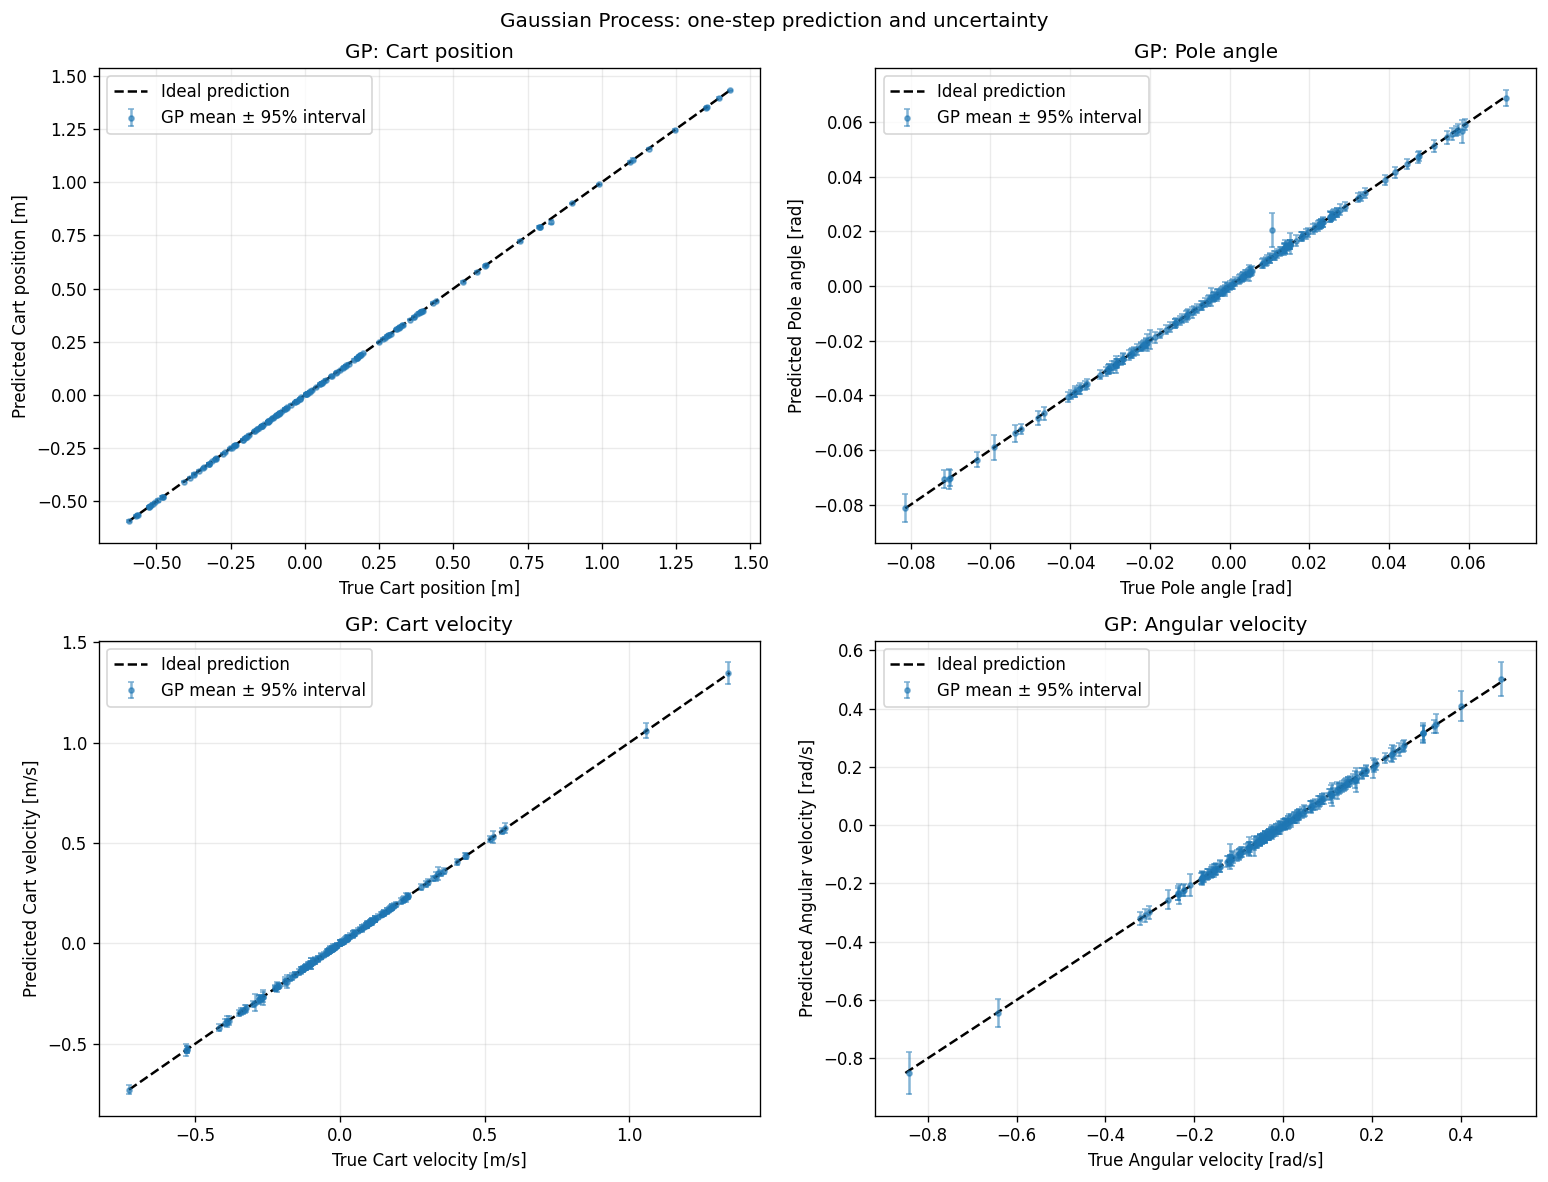

In [15]:
plot_rng = np.random.default_rng(SEED + 99)
plot_indices = np.sort(
    plot_rng.choice(len(X_next_test), size=min(160, len(X_next_test)), replace=False)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for d, ax in enumerate(axes.flat):
    true_values = X_next_test[plot_indices, d]
    predicted_values = Xhat_gp[plot_indices, d]
    std_values = np.sqrt(np.maximum(Var_gp[plot_indices, d], 1e-12))

    ax.errorbar(
        true_values,
        predicted_values,
        yerr=1.96 * std_values,
        fmt="o",
        markersize=3,
        alpha=0.55,
        capsize=2,
        label="GP mean ± 95% interval"
    )

    lower = min(true_values.min(), predicted_values.min())
    upper = max(true_values.max(), predicted_values.max())
    ax.plot([lower, upper], [lower, upper], "k--", label="Ideal prediction")
    ax.set_xlabel(f"True {STATE_NAMES[d]} [{STATE_UNITS[d]}]")
    ax.set_ylabel(f"Predicted {STATE_NAMES[d]} [{STATE_UNITS[d]}]")
    ax.set_title(f"GP: {STATE_NAMES[d]}")
    ax.legend()

plt.suptitle("Gaussian Process: one-step prediction and uncertainty")
plt.tight_layout()
plt.show()

## 15. Open-loop multi-step prediction

One-step prediction uses the measured state at each time step. In an open-loop rollout, the model's previous prediction becomes its next state input:

$$
\widehat x_{k+1}=\widehat F(\widehat x_k,u_k),
\qquad \widehat x_0=x_0.
$$

A small one-step error can therefore grow over time. This is especially important for the upright cart–pole, which is an unstable system without feedback.

Every model is given the same initial state and the same recorded input sequence from each test trajectory. The input sequence is replayed as recorded; it is not recalculated from the predicted state. The reported errors are aggregated over the independent test trajectories.

In [16]:
def predict_one_step(model_name, state, force):
    """Predict the next state from a state and force in physical units."""
    z = np.concatenate([state, [force]]).reshape(1, -1)

    if model_name == "MLP":
        delta = predict_nn_delta(nn_model, z)[0]
    elif model_name == "GP":
        delta, _ = predict_gp_delta(gp_models, gp_likelihoods, z)
        delta = delta[0]
    elif model_name == "Hybrid":
        delta = predict_hybrid_delta(hybrid_model, z)[0]
    elif model_name == "Physics reference":
        return plant.rk4_step(state, force, DT)
    else:
        raise ValueError(f"Unknown model: {model_name}")

    return state + delta


def rollout_trajectory(model_name, trajectory, max_steps=None):
    states_true = trajectory["states"]
    inputs = trajectory["inputs"]
    n_steps = len(inputs) if max_steps is None else min(len(inputs), max_steps)

    predicted = np.zeros((n_steps + 1, 4))
    predicted[0] = states_true[0]

    for k in range(n_steps):
        predicted[k + 1] = predict_one_step(
            model_name,
            predicted[k],
            inputs[k]
        )

    return states_true[:n_steps + 1], predicted, inputs[:n_steps]


ROLLOUT_MODELS = ["MLP", "GP", "Hybrid", "Physics reference"]
N_ROLLOUT_TESTS = len(test_trajectories)
rollout_records = {name: [] for name in ROLLOUT_MODELS}

for trajectory in test_trajectories[:N_ROLLOUT_TESTS]:
    for model_name in ROLLOUT_MODELS:
        true_states, predicted_states, applied_inputs = rollout_trajectory(
            model_name, trajectory
        )
        rollout_records[model_name].append((true_states, predicted_states))

# Horizon-dependent cumulative RMSE. Each point aggregates all test trajectories
# and all time samples from t=0 up to the indicated horizon.
horizon_steps = [1, 5, 10, 20, 40, 60]
rollout_rmse = {name: np.zeros((len(horizon_steps), 4)) for name in ROLLOUT_MODELS}

for model_name, records in rollout_records.items():
    for h_index, horizon in enumerate(horizon_steps):
        squared_errors = []
        for true_states, predicted_states in records:
            horizon = min(horizon, len(true_states) - 1)
            squared_errors.append(
                (predicted_states[:horizon + 1] - true_states[:horizon + 1])**2
            )
        concatenated = np.concatenate(squared_errors, axis=0)
        rollout_rmse[model_name][h_index] = np.sqrt(np.mean(concatenated, axis=0))

print("CUMULATIVE ROLLOUT RMSE BY HORIZON")
for h_index, h in enumerate(horizon_steps):
    print(f"\nHorizon: {h} steps ({h * DT:.2f} s)")
    for model_name in ROLLOUT_MODELS:
        values = rollout_rmse[model_name][h_index]
        print(f"{model_name:18s}: " + ", ".join(
            f"{STATE_NAMES[d]}={values[d]:.4f}" for d in range(4)
        ))

CUMULATIVE ROLLOUT RMSE BY HORIZON

Horizon: 1 steps (0.05 s)
MLP               : Cart position=0.0013, Pole angle=0.0009, Cart velocity=0.0091, Angular velocity=0.0047
GP                : Cart position=0.0023, Pole angle=0.0017, Cart velocity=0.0160, Angular velocity=0.0153
Hybrid            : Cart position=0.0000, Pole angle=0.0001, Cart velocity=0.0011, Angular velocity=0.0021
Physics reference : Cart position=0.0000, Pole angle=0.0000, Cart velocity=0.0000, Angular velocity=0.0000

Horizon: 5 steps (0.25 s)
MLP               : Cart position=0.0066, Pole angle=0.0035, Cart velocity=0.0165, Angular velocity=0.0075
GP                : Cart position=0.0123, Pole angle=0.0069, Cart velocity=0.0239, Angular velocity=0.0340
Hybrid            : Cart position=0.0002, Pole angle=0.0005, Cart velocity=0.0019, Angular velocity=0.0032
Physics reference : Cart position=0.0000, Pole angle=0.0000, Cart velocity=0.0000, Angular velocity=0.0000

Horizon: 10 steps (0.50 s)
MLP               : Cart po

### Plot one test rollout

The plot shows one test trajectory as an example. The horizon-dependent error table above uses all test trajectories. The angle is kept unwrapped in both the simulator and the predictions, so it can move beyond $\pm\pi$ if the pole rotates. Do not wrap only one of the two trajectories when calculating the error.

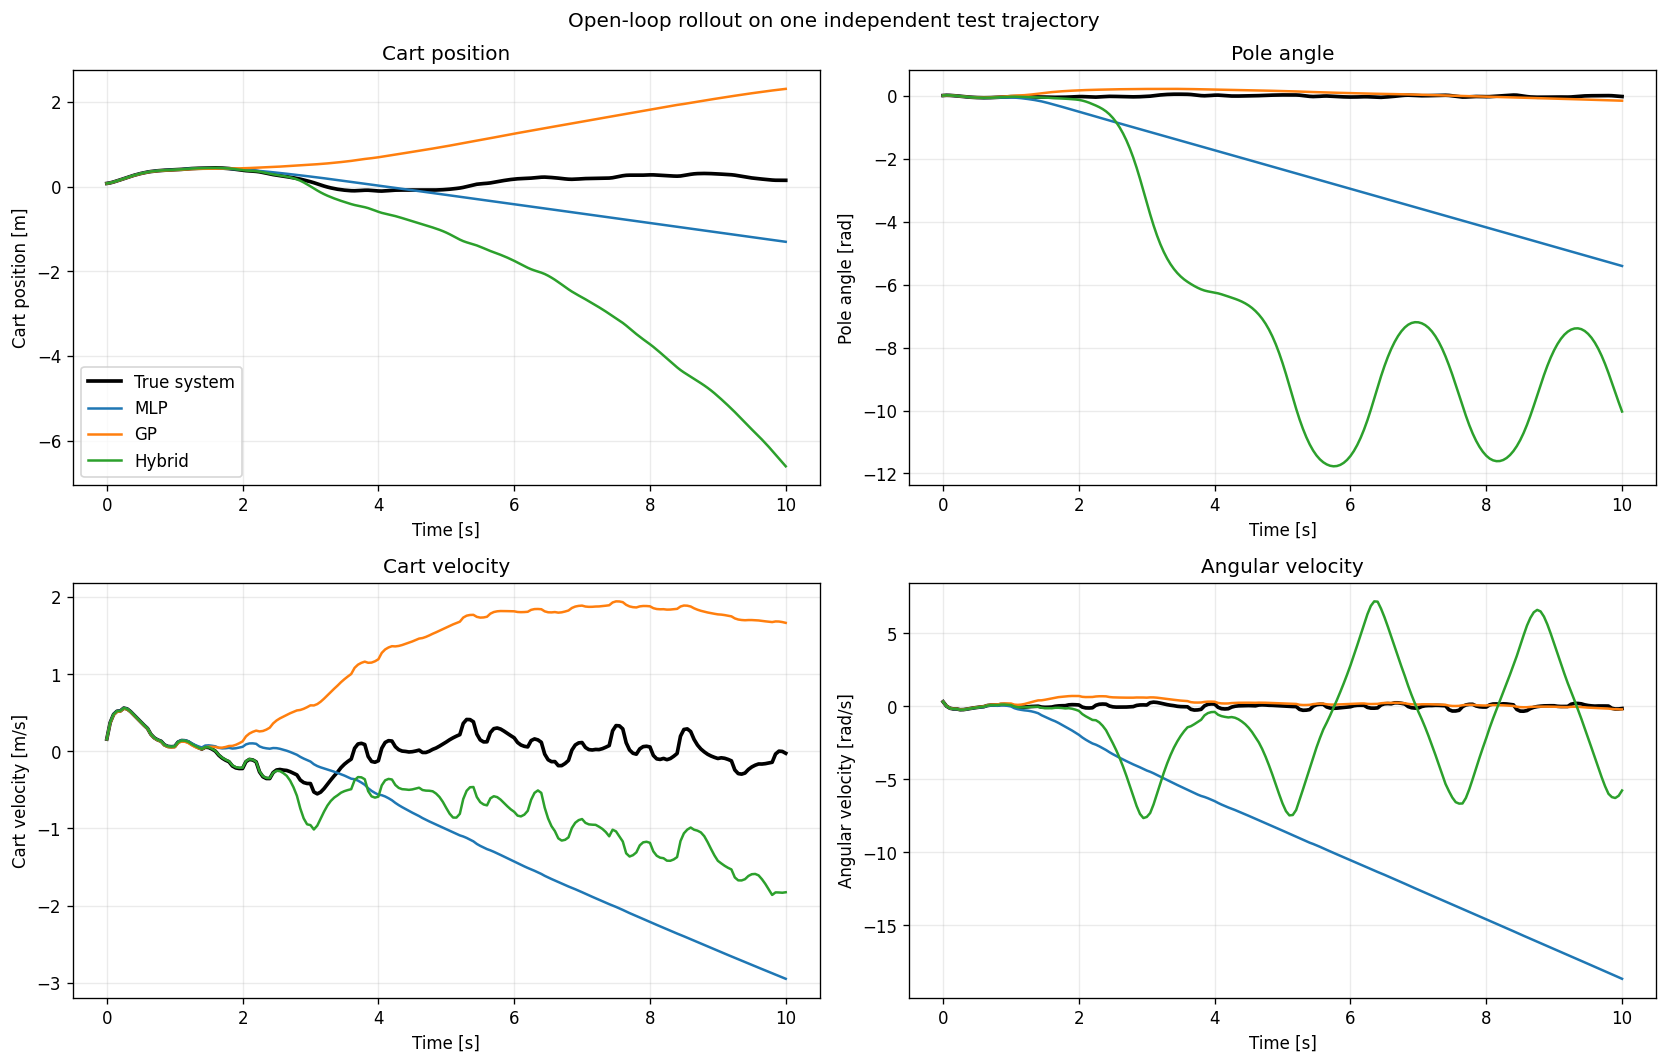

In [18]:
representative = test_trajectories[0]
true_states = representative["states"]
time = representative["time"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
representative_predictions = {
    model_name: rollout_trajectory(model_name, representative)[1]
    for model_name in ["MLP", "GP", "Hybrid"]
}

for d, ax in enumerate(axes.flat):
    ax.plot(time, true_states[:, d], "k-", linewidth=2.2, label="True system")

    for model_name, prediction in representative_predictions.items():
        ax.plot(time[:len(prediction)], prediction[:, d], label=model_name)

    ax.set_title(STATE_NAMES[d])
    ax.set_xlabel("Time [s]")
    ax.set_ylabel(f"{STATE_NAMES[d]} [{STATE_UNITS[d]}]")

axes[0, 0].legend()
plt.suptitle("Open-loop rollout on one independent test trajectory")
plt.tight_layout()
plt.show()

# Plot average rollout error versus horizon (NRMSE, averaged over states).
#plt.figure(figsize=(9, 5))
#for model_name in ROLLOUT_MODELS:
#    average_nrmse = np.mean(rollout_rmse[model_name] / state_scale, axis=1)
#    plt.plot(np.array(horizon_steps) * DT, average_nrmse, "o-", label=model_name)
#plt.xlabel("Prediction horizon [s]")
#plt.ylabel("Mean state NRMSE")
#plt.title("Open-loop error accumulation across test trajectories")
#plt.legend()
#plt.tight_layout()
#plt.show()

## 16. Fine-tune the model with a multi-step loss

The one-step training objective penalises the error at the next sample. It does not directly penalise the error after several predictions have been fed back into the model.

For a horizon of $H$ samples, the predicted states are generated recursively:

$$
\widehat x_{k+j+1}=\widehat F(\widehat x_{k+j},u_{k+j}),
\qquad j=0,\ldots,H-1.
$$

We use the sequence loss

$$
J_H(\vartheta)=\frac{1}{H}\sum_{j=1}^{H}
\left\|D_x^{-1}(\widehat x_{k+j}-x_{k+j})\right\|_2^2,
$$

where $D_x=\operatorname{diag}(s_{x,1},\ldots,s_{x,4})$ scales the four state errors. This loss measures the error produced by recursive prediction, rather than only the first step.

The MLP and hybrid models are fine-tuned on short windows from the training trajectories. Validation windows are used to select the best weights. Test trajectories are not used during fine-tuning. The GP is not fine-tuned in this section.

In [52]:
def make_sequence_windows(trajectories, horizon=10, stride=1):
    initial_states, input_windows, target_windows = [], [], []
    for trajectory in trajectories:
        states = trajectory["states"]
        inputs = trajectory["inputs"]
        n_steps = len(inputs)
        for start in range(0, n_steps - horizon + 1, stride):
            initial_states.append(states[start])
            input_windows.append(inputs[start:start + horizon])
            target_windows.append(states[start + 1:start + horizon + 1])

    return (
        np.asarray(initial_states, dtype=np.float32),
        np.asarray(input_windows, dtype=np.float32),
        np.asarray(target_windows, dtype=np.float32)
    )


def sequence_loss(model, x0_batch, u_window, target_window, scaler_Z, scaler_D, state_scale_tensor):
    """Compute the average state error over a rollout window."""
    x_pred = x0_batch
    total_loss = 0.0

    z_mean = torch.tensor(scaler_Z.mean_, dtype=torch.float32, device=device)
    z_scale = torch.tensor(scaler_Z.scale_, dtype=torch.float32, device=device)
    d_mean = torch.tensor(scaler_D.mean_, dtype=torch.float32, device=device)
    d_scale = torch.tensor(scaler_D.scale_, dtype=torch.float32, device=device)

    horizon = u_window.shape[1]
    for j in range(horizon):
        z_physical = torch.cat([x_pred, u_window[:, j:j+1]], dim=1)
        z_normalized = (z_physical - z_mean) / z_scale

        delta_normalized = model(z_normalized)
        delta_physical = delta_normalized * d_scale + d_mean
        x_pred = x_pred + delta_physical

        normalized_error = (x_pred - target_window[:, j, :]) / state_scale_tensor
        total_loss = total_loss + torch.mean(normalized_error**2)

    return total_loss / horizon


def fine_tune_multistep(
    model,
    train_trajectories,
    val_trajectories,
    scaler_Z,
    scaler_D,
    state_scale,
    model_kind="mlp",
    horizon=10,
    epochs=50,
    batch_size=64,
    learning_rate=2e-4,
    patience=10
):
    """Fine-tune the model using short, differentiable rollouts."""
    train_arrays = make_sequence_windows(train_trajectories, horizon=horizon)
    val_arrays = make_sequence_windows(val_trajectories, horizon=horizon)

    train_ds = TensorDataset(*[
        torch.tensor(array, dtype=torch.float32) for array in train_arrays
    ])
    val_tensors = [
        torch.tensor(array, dtype=torch.float32, device=device) for array in val_arrays
    ]

    loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED + 10)
    )

    if model_kind == "hybrid":
        parameters = list(model.residual_network.parameters())
    else:
        parameters = list(model.parameters())

    optimizer = optim.AdamW(parameters, lr=learning_rate, weight_decay=1e-6)
    state_scale_tensor = torch.tensor(state_scale, dtype=torch.float32, device=device)

    best_val = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    no_improvement = 0
    history = {"train": [], "validation": []}

    for epoch in range(epochs):
        model.train()
        batch_losses = []

        for x0_b, u_b, target_b in loader:
            x0_b = x0_b.to(device)
            u_b = u_b.to(device)
            target_b = target_b.to(device)

            loss = sequence_loss(
                model, x0_b, u_b, target_b,
                scaler_Z, scaler_D, state_scale_tensor
            )

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(parameters, max_norm=5.0)
            optimizer.step()
            batch_losses.append(float(loss.item()))

        model.eval()
        with torch.no_grad():
            val_loss = sequence_loss(
                model, val_tensors[0], val_tensors[1], val_tensors[2],
                scaler_Z, scaler_D, state_scale_tensor
            ).item()

        train_loss = float(np.mean(batch_losses))
        history["train"].append(train_loss)
        history["validation"].append(val_loss)

        if val_loss < best_val - 1e-5:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= patience:
            print(f"{model_kind} multi-step fine-tuning stopped at epoch {epoch + 1}")
            break

    model.load_state_dict(best_state)
    print(f"{model_kind} best validation rollout loss: {best_val:.6f}")
    return model, history


# Keep the original models so their results can be compared with fine-tuned copies.
RUN_MULTISTEP_FINETUNING = True

if RUN_MULTISTEP_FINETUNING:
    nn_model_multistep = copy.deepcopy(nn_model).to(device)
    nn_model_multistep, nn_ms_history = fine_tune_multistep(
        nn_model_multistep,
        train_trajectories, val_trajectories,
        scaler_Z, scaler_D, state_scale,
        model_kind="mlp", horizon=10, epochs=50
    )

    hybrid_model_multistep = copy.deepcopy(hybrid_model).to(device)
    hybrid_model_multistep, hybrid_ms_history = fine_tune_multistep(
        hybrid_model_multistep,
        train_trajectories, val_trajectories,
        scaler_Z, scaler_D, state_scale,
        model_kind="hybrid", horizon=10, epochs=50
    )

mlp multi-step fine-tuning stopped at epoch 27
mlp best validation rollout loss: 0.000606
hybrid multi-step fine-tuning stopped at epoch 14
hybrid best validation rollout loss: 0.000022


### Compare the original and fine-tuned models

The original and fine-tuned MLP and hybrid models are evaluated on the same held-out test trajectories. Keep the fine-tuned version only if its validation results support the change. Fine-tuning may improve rollout error while slightly increasing one-step error, so both measures should be checked.

In [53]:
if RUN_MULTISTEP_FINETUNING:
    # Prediction helper for the fine-tuned models.
    def predict_with_model_object(model, state, force):
        z = np.concatenate([state, [force]]).reshape(1, -1)
        z_n = scaler_Z.transform(z)
        model.eval()
        with torch.no_grad():
            d_n = model(torch.tensor(z_n, dtype=torch.float32, device=device)).cpu().numpy()
        return state + scaler_D.inverse_transform(d_n)[0]

    def rollout_custom_predictor(predictor, trajectory):
        states = trajectory["states"]
        inputs = trajectory["inputs"]
        prediction = np.zeros_like(states)
        prediction[0] = states[0]
        for k, force in enumerate(inputs):
            prediction[k + 1] = predictor(prediction[k], force)
        return states, prediction

    comparison_predictors = {
        "MLP one-step": lambda x, u: predict_one_step("MLP", x, u),
        "MLP multi-step": lambda x, u: predict_with_model_object(nn_model_multistep, x, u),
        "Hybrid one-step": lambda x, u: predict_one_step("Hybrid", x, u),
        "Hybrid multi-step": lambda x, u: predict_with_model_object(hybrid_model_multistep, x, u),
    }

    print("\nHeld-out rollout RMSE over all test trajectories:")
    for name, predictor in comparison_predictors.items():
        squared = []
        for trajectory in test_trajectories:
            true_states, predicted_states = rollout_custom_predictor(predictor, trajectory)
            squared.append((predicted_states[1:] - true_states[1:])**2)
        rmse = np.sqrt(np.mean(np.concatenate(squared, axis=0), axis=0))
        print(name, ":", np.round(rmse, 5))


Held-out rollout RMSE over all test trajectories:
MLP one-step : [0.17411 0.58201 0.4581  2.89104]
MLP multi-step : [0.15779 0.53382 0.42991 2.65207]
Hybrid one-step : [0.02271 1.71995 0.09224 2.92872]
Hybrid multi-step : [0.0222  1.81617 0.09415 3.03203]


## 18. Experiment — measurement noise

The main experiment uses noise-free simulated measurements. This makes it easier to check the identification pipeline before adding sensor effects.

A simple measurement model is

$$
y_k=x_k+\nu_k,
\qquad \nu_k\sim\mathcal N(0,R).
$$

The measured increment is then

$$
\widetilde{\Delta x}_k=y_{k+1}-y_k
=\Delta x_k+(\nu_{k+1}-\nu_k).
$$

The optional experiment adds independent Gaussian noise to the measured states. The applied force is assumed to be known exactly. This setup does not model sensor bias, time-correlated noise, quantisation, or missing measurements.

The experiment is disabled by default because it retrains all three models at each noise level. Exact GP fitting can make it slow. Set `RUN_NOISE_EXPERIMENT = True` after the main notebook has run successfully.

In [19]:
RUN_NOISE_EXPERIMENT = False

if RUN_NOISE_EXPERIMENT:
    noise_levels = [0.0, 0.02, 0.05, 0.10]  # fraction of training-state std
    noise_results = {"MLP": [], "GP": [], "Hybrid": []}

    for noise_level in noise_levels:
        rng = np.random.default_rng(SEED + int(noise_level * 10000) + 200)

        def noisy_transition_arrays(trajectories):
            X_parts, U_parts, D_parts = [], [], []
            for trajectory in trajectories:
                states = trajectory["states"]
                inputs = trajectory["inputs"]
                noise = rng.normal(
                    0.0,
                    noise_level * state_scale,
                    size=states.shape
                )
                measured_states = states + noise
                X_parts.append(measured_states[:-1])
                U_parts.append(inputs.reshape(-1, 1))
                D_parts.append(measured_states[1:] - measured_states[:-1])
            Xn = np.vstack(X_parts)
            Un = np.vstack(U_parts)
            Dn = np.vstack(D_parts)
            return np.hstack([Xn, Un]), Dn, Xn

        Ztr_raw, Dtr_raw, _ = noisy_transition_arrays(train_trajectories)
        Zva_raw, Dva_raw, _ = noisy_transition_arrays(val_trajectories)
        Zte_raw, _, Xte_measured = noisy_transition_arrays(test_trajectories)

        sz_noise = StandardScaler().fit(Ztr_raw)
        sd_noise = StandardScaler().fit(Dtr_raw)
        Ztr_n = sz_noise.transform(Ztr_raw)
        Dtr_n = sd_noise.transform(Dtr_raw)
        Zva_n = sz_noise.transform(Zva_raw)
        Dva_n = sd_noise.transform(Dva_raw)
        Zte_n = sz_noise.transform(Zte_raw)

        # The reference next states are clean; the regressors are noisy.
        _, _, Xte_clean, _, Xnext_te_clean = pack_transitions(test_trajectories)

        # MLP
        model_nn_noise = DynamicsMLP()
        model_nn_noise, _ = train_supervised_model(
            model_nn_noise, Ztr_n, Dtr_n, Zva_n, Dva_n,
            epochs=200, learning_rate=1e-3, description=f"MLP noise={noise_level}"
        )
        with torch.no_grad():
            pred_n = model_nn_noise(
                torch.tensor(Zte_n, dtype=torch.float32, device=device)
            ).cpu().numpy()
        pred_delta = sd_noise.inverse_transform(pred_n)
        pred_next = Xte_measured + pred_delta
        noise_results["MLP"].append(
            np.mean(np.sqrt(np.mean((Xnext_te_clean - pred_next)**2, axis=0) / (state_scale**2)))
        )

        # GP
        models_noise, likes_noise, _ = train_gp_multioutput(
            Ztr_n, Dtr_n, Zva_n, Dva_n,
            training_iterations=45, learning_rate=0.06
        )
        pred_n, _ = predict_gp_multioutput(models_noise, likes_noise, Zte_n)
        pred_delta = sd_noise.inverse_transform(pred_n)
        pred_next = Xte_measured + pred_delta
        noise_results["GP"].append(
            np.mean(np.sqrt(np.mean((Xnext_te_clean - pred_next)**2, axis=0) / (state_scale**2)))
        )

        # Hybrid: construct the model with the noise-specific training scalers.
        model_hybrid_noise = HybridResidualModel(plant, sz_noise, sd_noise).to(device)
        model_hybrid_noise, _ = train_supervised_model(
            model_hybrid_noise, Ztr_n, Dtr_n, Zva_n, Dva_n,
            epochs=200, learning_rate=1e-3,
            trainable_parameters=model_hybrid_noise.residual_network.parameters(),
            description=f"Hybrid noise={noise_level}"
        )
        with torch.no_grad():
            pred_n = model_hybrid_noise(
                torch.tensor(Zte_n, dtype=torch.float32, device=device)
            ).cpu().numpy()
        pred_delta = sd_noise.inverse_transform(pred_n)
        pred_next = Xte_measured + pred_delta
        noise_results["Hybrid"].append(
            np.mean(np.sqrt(np.mean((Xnext_te_clean - pred_next)**2, axis=0) / (state_scale**2)))
        )

    plt.figure(figsize=(8, 5))
    for model_name, values in noise_results.items():
        plt.plot(np.array(noise_levels) * 100, values, "o-", label=model_name)
    plt.xlabel("Measurement noise (% of training state standard deviation)")
    plt.ylabel("Mean state NRMSE")
    plt.title("Measurement-noise robustness")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 19. Experiment — data efficiency

This experiment trains the models with increasingly large subsets of the training transitions. A new pair of scalers is fitted for each subset. Validation and test data are transformed with those scalers but are never used to fit them.

The test set stays the same for every subset size. Exact GP training can become expensive as the subset grows, so this experiment is disabled by default.

In [20]:
RUN_DATA_EFFICIENCY_EXPERIMENT = False

if RUN_DATA_EFFICIENCY_EXPERIMENT:
    subset_sizes = [150, 300, 600, len(Z_train)]
    data_efficiency_results = {"MLP": [], "GP": [], "Hybrid": []}
    subset_rng = np.random.default_rng(SEED + 500)

    for n_samples in subset_sizes:
        print(f"\nData-efficiency experiment: {n_samples} training transitions")
        indices = subset_rng.choice(len(Z_train), size=n_samples, replace=False)

        Z_sub, D_sub = Z_train[indices], D_train[indices]
        sz_sub = StandardScaler().fit(Z_sub)
        sd_sub = StandardScaler().fit(D_sub)

        Z_sub_n = sz_sub.transform(Z_sub)
        D_sub_n = sd_sub.transform(D_sub)
        Z_val_sub_n = sz_sub.transform(Z_val)
        D_val_sub_n = sd_sub.transform(D_val)
        Z_test_sub_n = sz_sub.transform(Z_test)

        # MLP
        m_nn = DynamicsMLP()
        m_nn, _ = train_supervised_model(
            m_nn, Z_sub_n, D_sub_n, Z_val_sub_n, D_val_sub_n,
            epochs=200, description=f"MLP n={n_samples}"
        )
        with torch.no_grad():
            d_n = m_nn(torch.tensor(Z_test_sub_n, dtype=torch.float32, device=device)).cpu().numpy()
        d_pred = sd_sub.inverse_transform(d_n)
        x_pred = X_test + d_pred
        data_efficiency_results["MLP"].append(
            np.mean(np.sqrt(np.mean((X_next_test - x_pred)**2, axis=0) / state_scale**2))
        )

        # GP
        gp_m, gp_l, _ = train_gp_multioutput(
            Z_sub_n, D_sub_n, Z_val_sub_n, D_val_sub_n,
            training_iterations=55, learning_rate=0.06
        )
        d_n, _ = predict_gp_multioutput(gp_m, gp_l, Z_test_sub_n)
        d_pred = sd_sub.inverse_transform(d_n)
        x_pred = X_test + d_pred
        data_efficiency_results["GP"].append(
            np.mean(np.sqrt(np.mean((X_next_test - x_pred)**2, axis=0) / state_scale**2))
        )

        # Hybrid
        m_h = HybridResidualModel(plant, sz_sub, sd_sub).to(device)
        m_h, _ = train_supervised_model(
            m_h, Z_sub_n, D_sub_n, Z_val_sub_n, D_val_sub_n,
            epochs=200,
            trainable_parameters=m_h.residual_network.parameters(),
            description=f"Hybrid n={n_samples}"
        )
        with torch.no_grad():
            d_n = m_h(torch.tensor(Z_test_sub_n, dtype=torch.float32, device=device)).cpu().numpy()
        d_pred = sd_sub.inverse_transform(d_n)
        x_pred = X_test + d_pred
        data_efficiency_results["Hybrid"].append(
            np.mean(np.sqrt(np.mean((X_next_test - x_pred)**2, axis=0) / state_scale**2))
        )

    plt.figure(figsize=(8, 5))
    for model_name, values in data_efficiency_results.items():
        plt.plot(subset_sizes, values, "o-", label=model_name)
    plt.xscale("log")
    plt.xlabel("Number of training transitions")
    plt.ylabel("Mean state NRMSE")
    plt.title("Data efficiency")
    plt.legend()
    plt.tight_layout()
    plt.show()